# BERT Hash, static embeddings, MiniLM, BGE-small, GTE-tiny and Ettin — Colab L4

A self-contained **frozen-encoder benchmark**, adapted from notebooks 06–08. Select **Runtime → Change runtime type → L4 GPU**, edit the settings below, and run all cells. No training or A100 is required. Colab GPU availability depends on your account and current capacity.

The default evaluates the six BERT Hash base/embedding checkpoints, three static baselines, MiniLM, BGE-small, GTE-tiny, and every exit/dimension of your trained Ettin export. Quality tasks are the complete pinned NanoNQ, NanoHotpotQA, NanoMSMARCO corpora and Twitter URL test. Fresh GoEmotions/TweetTopic classifier probes are optional.

**Before running:** set `ETTIN_EXPORT` to an existing notebook 06/08 `exports/social-encoder` folder on Drive, or an extracted copy of your local `social-encoder/`. The notebook verifies its manifest, then copies it to the Colab SSD. No repository checkout or companion JSON is needed. Set `INCLUDE_ETTIN=False` only if deliberately benchmarking the public models alone.

L4 settings: one model process at a time, float32 inference, 256-token cap, batch 32, disk-backed CPU vectors, blocked exact search. Static quality inference uses CPU; GPU timing is labeled separately. Completed model/task bundles are checksummed and copied to Drive. Re-running unchanged settings resumes verified work. Changing the worker, model revisions, hardware, environment, or settings creates a new configuration directory.

Start with `SMOKE=True` to test installation and Drive paths. Smoke uses tiny queries/candidate fixtures and is **not a quality result**. Switch it to `False` for the full run. No wall-time guarantee is assumed; each completed task is durable at the next verified Drive copy.

Sources: [NeuML base](https://huggingface.co/NeuML/bert-hash-femto), [embedding family](https://huggingface.co/NeuML/bert-hash-nano-embeddings), [POTION](https://huggingface.co/minishlab/potion-base-8M), [Static Retrieval](https://huggingface.co/sentence-transformers/static-retrieval-mrl-en-v1), [Colab FAQ](https://research.google.com/colaboratory/faq.html).

## 1. Install into a fresh Colab runtime
Keep Colab's CUDA-enabled PyTorch. If you already imported another Transformers version, restart the session after this cell, then run from the settings cell.

The pinned NeuML model code needs a newer Transformers API than Ettin's tested 5.1.0 path. Install **5.17.0 + tokenizers 0.23.1 into a separate directory** used only by hash subprocesses. Other workers use Transformers 5.1.0. Hash snapshots include custom Python code loaded with `trust_remote_code=True`; their immutable revisions are embedded below. The base hash pooler is unused and is not instantiated.

In [9]:
%pip install -q transformers==5.1.0 tokenizers==0.22.2 huggingface-hub==1.5.0 safetensors==0.8.0 regex==2025.11.3 typer==0.21.1 datasets==4.5.0 sentence-transformers==5.2.2 scikit-learn==1.7.2 onnxruntime==1.24.1 pandas matplotlib
%pip install -q --upgrade --no-deps --target /content/bert-hash-transformers-5.17 transformers==5.17.0 tokenizers==0.23.1

## 2. Settings
Default scope is full retrieval + paraphrase quality, paired retrieval intervals, CPU timings, and supported GPU timings. CPU timings compare the actual library backends on this Colab host; they are not portable predictions for your own CPU.

`RUN_PROBES=True` adds frozen classifiers for all dimensions/exits and can spend substantial time on CPU. `TWITTER_GROUP_BOOTSTRAP=True` adds paired AP intervals over connected tweet groups for the three embedding-tuned hash candidates and GTE-tiny versus the current static baseline. Both preserve the test splits. Existing Ettin emotion/topic training means the probes do not represent equal prior supervision.

Timing uses a fixed 128-text panel, batch 1/32, ten warmups and three passes. To save GPU rental time it measures Ettin depths 1/3/5/9 plus full depth; **quality still covers every exported exit**. Edit the depth list for a different export. Timings measure document encoding from strings to normalized float32 CPU vectors; BGE query-prefix latency is not included in this compact timing suite.

For a focused GTE-tiny screen, set `MODEL_IDS` to `["TaylorAI/gte-tiny", "futur/Qwen3-Embedding-0.6B-model2vec-onnx", "sentence-transformers/all-MiniLM-L6-v2", "BAAI/bge-small-en-v1.5"]`. This selection does not require an Ettin export. Leave `MODEL_IDS=None` to include GTE-tiny in the complete comparison.


In [10]:
RUN_NAME = 'bert-hash-l4-01'
ETTIN_EXPORT = '/content/drive/MyDrive/encoder_experiments/ettin-social-unified-02/exports/social-encoder'
INCLUDE_ETTIN = True
INCLUDE_BASE_HASH = True
MODEL_IDS = None  # Optional exact ID list for a deliberately smaller, separately identified run.
SMOKE = False
MAX_LENGTH = 256
BATCH_SIZE = 32  # If memory fails, use 16 and rerun; the new configuration is saved separately.
CPU_THREADS = 2
ETTIN_DEPTHS = None  # None = all exported early exits, plus full depth automatically.
TIMING_ETTIN_DEPTHS = [1, 3, 5, 9]  # Unavailable depths are ignored; full depth is always timed.
RUN_PROBES = False
RUN_LATENCY = True
GPU_TIMINGS = True
TWITTER_GROUP_BOOTSTRAP = False
RELEASE_WHEN_DONE = True  # Optional verified Drive flush and Colab release at the end.

## 3. Immutable model and data registry
Hash vectors are dense float32 vectors, not binary hashes. Use native 50/80/128D for hash models, native 384D for BGE/MiniLM/GTE-tiny, and only trained prefixes for Ettin/Static Retrieval. The chosen Drive export supplies Ettin's actual depths, dimensions, and identity; the reference manifest's local development hash is replaced after verification.

POTION is loaded through its published Sentence Transformers `StaticEmbedding` representation here, rather than the Model2Vec runtime proposed in the broader design. This makes token-ID truncation explicit and is recorded in every result. Static token weighting is already in the released table. The current Qwen Model2Vec ONNX export retains the project's packed-token/offset adapter.

[GTE-tiny](https://huggingface.co/TaylorAI/gte-tiny) uses masked mean pooling, no query prefix, and full 384D L2-normalized vectors. Model parameters are explicitly converted to float32 even when checkpoint metadata advertises float16. First judge this unquantized checkpoint on the shared tasks. If its quality is suitable, benchmark `onnx/model_quantized.onnx` from the same pinned revision separately against this reference, checking retrieval/AP loss, actual CPU latency and model bytes. INT8 inference does not imply INT8 output vectors, a smaller 384D index, or an L4 speedup. No ONNX INT8 deployment change is made by this notebook.


In [11]:
import json
MANIFEST = json.loads(r'''
{
  "schema_version": 1,
  "metadata_checked_date": "2026-09-28",
  "models": [
    {
      "id": "NeuML/bert-hash-femto-embeddings",
      "revision": "8904627df4fd38d59cb1e9c4ff389b909152b627",
      "group": "hash_embeddings",
      "native_dimension": 50,
      "dimensions": [
        50
      ],
      "pooling": "masked_mean",
      "backend": "pytorch",
      "requires_custom_code": true
    },
    {
      "id": "NeuML/bert-hash-pico-embeddings",
      "revision": "b2bd0ac66c1dd502ba201baffc67e555a9f8f2ea",
      "group": "hash_embeddings",
      "native_dimension": 80,
      "dimensions": [
        80
      ],
      "pooling": "masked_mean",
      "backend": "pytorch",
      "requires_custom_code": true
    },
    {
      "id": "NeuML/bert-hash-nano-embeddings",
      "revision": "0ce54d70c762703aa3330b9331db02e2bb1f741d",
      "group": "hash_embeddings",
      "native_dimension": 128,
      "dimensions": [
        128
      ],
      "pooling": "masked_mean",
      "backend": "pytorch",
      "requires_custom_code": true
    },
    {
      "id": "NeuML/bert-hash-femto",
      "revision": "7c69f354d282a573c1dc01d629d8025f9ad66927",
      "group": "hash_base_control",
      "native_dimension": 50,
      "dimensions": [
        50
      ],
      "pooling": "masked_mean",
      "backend": "pytorch",
      "requires_custom_code": true
    },
    {
      "id": "NeuML/bert-hash-pico",
      "revision": "a77918cf332dbb800576ffbd095822f1f42e0e08",
      "group": "hash_base_control",
      "native_dimension": 80,
      "dimensions": [
        80
      ],
      "pooling": "masked_mean",
      "backend": "pytorch",
      "requires_custom_code": true
    },
    {
      "id": "NeuML/bert-hash-nano",
      "revision": "7f9b214a163c964331fcc59d9d0e4b06d1db51dd",
      "group": "hash_base_control",
      "native_dimension": 128,
      "dimensions": [
        128
      ],
      "pooling": "masked_mean",
      "backend": "pytorch",
      "requires_custom_code": true
    },
    {
      "id": "futur/Qwen3-Embedding-0.6B-model2vec-onnx",
      "revision": "a3f60a85a2570e7976ea7f2d6505ad3e5152a96f",
      "group": "current_static",
      "native_dimension": 256,
      "dimensions": [
        256
      ],
      "pooling": "published_export",
      "backend": "onnxruntime"
    },
    {
      "id": "minishlab/potion-base-8M",
      "revision": "bf8b056651a2c21b8d2565580b8569da283cab23",
      "group": "static",
      "native_dimension": 256,
      "dimensions": [
        256
      ],
      "pooling": "published_adapter",
      "backend": "sentence_transformers"
    },
    {
      "id": "sentence-transformers/static-retrieval-mrl-en-v1",
      "revision": "f60985c706f192d45d218078e49e5a8b6f15283a",
      "group": "static",
      "native_dimension": 1024,
      "dimensions": [
        1024,
        256,
        128
      ],
      "pooling": "published_adapter",
      "backend": "sentence_transformers"
    },
    {
      "id": "sentence-transformers/all-MiniLM-L6-v2",
      "revision": "1110a243fdf4706b3f48f1d95db1a4f5529b4d41",
      "group": "small_transformer",
      "native_dimension": 384,
      "dimensions": [
        384
      ],
      "pooling": "masked_mean",
      "backend": "pytorch"
    },
    {
      "id": "BAAI/bge-small-en-v1.5",
      "revision": "5c38ec7c405ec4b44b94cc5a9bb96e735b38267a",
      "group": "small_transformer",
      "native_dimension": 384,
      "dimensions": [
        384
      ],
      "pooling": "cls",
      "backend": "pytorch",
      "retrieval_query_prefix": "Represent this sentence for searching relevant passages: "
    },
    {
      "id": "TaylorAI/gte-tiny",
      "revision": "4cc5e73d86a67c601897257b467187234aa3bca3",
      "group": "small_transformer",
      "native_dimension": 384,
      "dimensions": [
        384
      ],
      "pooling": "masked_mean",
      "backend": "pytorch"
    },
    {
      "id": "local/social-encoder",
      "path": "social-encoder",
      "group": "trained_ettin",
      "manifest_sha256": "97a70cec36a685fc7b1b8b8fe3a5ac5ed10fe6864fdde3d5a7cc76690129d480",
      "encoder_json_sha256": "34d8f68ab1ab278bc475fc1cbac0a805be6fd6d707a40b141ecfa08a5b7be0df",
      "native_dimension": 384,
      "dimensions": [
        128,
        256,
        384
      ],
      "exit_depths": [
        1,
        2,
        3,
        4,
        5,
        6,
        7,
        8,
        9
      ],
      "full_depth": 10,
      "pooling": "masked_mean_including_special_tokens",
      "backend": "pytorch",
      "retrieval_modes": [
        "same_exit",
        "full_corpus"
      ]
    }
  ],
  "datasets": [
    {
      "id": "sentence-transformers/NanoBEIR-en",
      "revision": "beb106fbcfaa599c508c667041bf8c85fd78736b",
      "tasks": [
        "NanoNQ",
        "NanoHotpotQA",
        "NanoMSMARCO"
      ],
      "candidate_policy": "complete_corpus"
    },
    {
      "id": "mteb/twitterurlcorpus-pairclassification",
      "revision": "ee5d15331196ec9f72e8393779b20098c10e29f6",
      "file": "test.json.gz"
    },
    {
      "id": "google-research-datasets/go_emotions",
      "revision": "add492243ff905527e67aeb8b80c082af02207c3",
      "subset": "simplified"
    },
    {
      "id": "cardiffnlp/tweet_topic_single",
      "revision": "87b7a0d1c402dbb481db649569c556d9aa27ac05",
      "split_stems": [
        "train_2020",
        "validation_2020",
        "test_2021"
      ]
    }
  ]
}
''')

## 4. Inline worker: adapters and correctness checks
These definition cells write the worker on the local SSD later. They do not start inference. Separate subprocesses release model memory between candidates and isolate the two Transformers versions. Every adapter checks native dimensions, finite nonzero outputs, repeatability and padding invariance. Ettin additionally checks full-forward parity and that early exits skip later backbone layers.

In [12]:
WORKER_PARTS = []
WORKER_PARTS.append(r'''
# Self-contained benchmark worker, emitted by notebook 09.
import os, sys, json, hashlib, shutil, uuid, time, gc, copy, gzip, platform, resource
from pathlib import Path, PurePosixPath
from collections import defaultdict
import importlib.metadata as metadata
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from transformers import AutoModel, AutoTokenizer
from huggingface_hub import hf_hub_download, snapshot_download
from safetensors.torch import load_file

def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False).encode()).hexdigest()

def sha(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for part in iter(lambda: f.read(8 * 1024 * 1024), b''):
            h.update(part)
    return h.hexdigest()

def write_json(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + '.tmp-' + uuid.uuid4().hex)
    tmp.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False))
    os.replace(tmp, path)

def text_id(text):
    return hashlib.sha256(' '.join(text.split()).casefold().encode()).hexdigest()

def safe_path(base, name):
    relative = PurePosixPath(name)
    if relative.is_absolute() or '..' in relative.parts or '\\' in name:
        raise ValueError(f'Unsafe relative artifact path: {name}')
    path = Path(base) / name
    if not path.resolve().is_relative_to(Path(base).resolve()):
        raise ValueError(f'Artifact path escapes root: {name}')
    return path

def verified(path, contract):
    path = Path(path)
    if not (path / 'COMMITTED.json').is_file():
        return False
    info = json.loads((path / 'COMMITTED.json').read_text())
    return info['contract'] == contract and all(
        safe_path(path, name).is_file() and sha(safe_path(path, name)) == value
        for name, value in info['checksums'].items())

def publish(local, remote, contract):
    local, remote = Path(local), Path(remote)
    files = {str(p.relative_to(local)): sha(p) for p in local.rglob('*')
             if p.is_file() and p.name != 'COMMITTED.json'}
    write_json(local / 'COMMITTED.json', dict(contract=contract, checksums=files))
    if remote.resolve() == local.resolve():
        return
    if remote.exists():
        if verified(remote, contract):
            return
        # Preserve incomplete/corrupt prior work for inspection, then recompute.
        remote.rename(remote.with_name(remote.name + '.incomplete-' + uuid.uuid4().hex))
    remote.parent.mkdir(parents=True, exist_ok=True)
    temp = remote.with_name('.uploading-' + uuid.uuid4().hex)
    shutil.copytree(local, temp)
    assert verified(temp, contract), 'Copy verification failed'
    os.replace(temp, remote)

def restore(remote, local, contract):
    remote, local = Path(remote), Path(local)
    if verified(local, contract):
        return True
    if not verified(remote, contract):
        return False
    shutil.copytree(remote, local, dirs_exist_ok=True)
    assert verified(local, contract)
    return True

def environment():
    def version(name):
        try: return metadata.version(name)
        except metadata.PackageNotFoundError: return None
    packages = ['torch', 'transformers', 'tokenizers', 'huggingface-hub', 'safetensors',
                'numpy', 'datasets', 'scikit-learn', 'onnxruntime', 'onnxruntime-gpu', 'sentence-transformers']
    return dict(python=sys.version, platform=platform.platform(),
                packages={p: version(p) for p in packages},
                gpu=torch.cuda.get_device_name() if torch.cuda.is_available() else None,
                cpu=platform.processor(), cpu_count=os.cpu_count(),
                threads=torch.get_num_threads(), affinity=sorted(os.sched_getaffinity(0)))

def normalized(z, dim):
    assert z.ndim == 2 and 0 < dim <= z.shape[1]
    z = np.asarray(z[:, :dim], dtype=np.float32)
    norms = np.linalg.norm(z, axis=1, keepdims=True)
    if not np.isfinite(z).all() or np.any(norms < 1e-8):
        raise ValueError('Nonfinite or zero vector; refusing to silently discard an evaluation row')
    return z / norms

def mean_pool(h, mask):
    w = mask.unsqueeze(-1).float()
    return (h.float() * w).sum(1) / w.sum(1).clamp_min(1)

class ExitHead(nn.Module):
    def __init__(self, backbone):
        super().__init__()
        self.norm = copy.deepcopy(backbone.final_norm)
        self.block = copy.deepcopy(backbone.layers[-1])
        self.block.gradient_checkpointing = False
    def forward(self, h, mask, masks, rope):
        kind = self.block.attention_type
        h = self.block(h, attention_mask=masks[kind], position_embeddings=rope[kind])
        return mean_pool(self.norm(h), mask)

class Encoder:
    def __init__(self, spec, config, device):
        self.spec, self.config, self.device = spec, config, device
        self.kind = spec['group']; self.cap = config['max_length']
        self.heads = None; self.static = self.kind in ('static', 'current_static')
        self.dimensions = spec['dimensions']; self.width = spec['native_dimension']
        self.depths = [0]; self.full_depth = 0
        self.prefix = spec.get('retrieval_query_prefix', '')
        start = time.perf_counter()
        if self.kind == 'trained_ettin':
            path = Path(config['ettin_local'])
            meta = json.loads((path / 'encoder.json').read_text())
            self.model = AutoModel.from_pretrained(path / 'backbone', attn_implementation='sdpa')
            self.tokenizer = AutoTokenizer.from_pretrained(path / 'tokenizer')
            self.full_depth = self.model.config.num_hidden_layers
            selected = meta['depths'] if config['ettin_depths'] is None else config['ettin_depths']
            assert set(selected) <= set(meta['depths'])
            self.depths = sorted(set(selected)) + [self.full_depth]
            self.dimensions = meta['dimensions']; self.width = self.model.config.hidden_size
            assert self.cap <= meta['max_length']
            self.heads = nn.ModuleDict({str(d): ExitHead(self.model) for d in meta['depths']})
            state = load_file(str(path / 'exits.safetensors'))
            self.heads.load_state_dict({k.removeprefix('heads.'): v for k, v in state.items()}, strict=True)
            self.heads.eval().requires_grad_(False).to(device)
            self.backend = 'pytorch/sdpa'
        else:
            if self.kind == 'current_static':
                patterns = ['onnx/model.onnx', 'tokenizer.json']
            elif self.static:
                patterns = ['*.json', '*.safetensors', '0_StaticEmbedding/*', '1_Normalize/*']
            else:
                patterns = ['*.json', '*.txt', '*.py', '*.safetensors']
            path = Path(snapshot_download(spec['id'], revision=spec['revision'], allow_patterns=patterns))
            if self.kind == 'current_static':
                import onnxruntime as ort
                from tokenizers import Tokenizer
                assert device == 'cpu', 'Current ONNX static baseline is explicitly CPU-only in this notebook'
                options = ort.SessionOptions(); options.intra_op_num_threads = torch.get_num_threads()
                options.inter_op_num_threads = 1
                self.model = ort.InferenceSession(str(path / 'onnx/model.onnx'), options,
                                                 providers=['CPUExecutionProvider'])
                self.tokenizer = Tokenizer.from_file(str(path / 'tokenizer.json'))
                self.tokenizer.no_padding(); self.tokenizer.no_truncation()
                self.backend = 'onnxruntime/CPUExecutionProvider'
            elif self.static:
                from sentence_transformers.models import StaticEmbedding
                sub = '0_StaticEmbedding' if (path / '0_StaticEmbedding').exists() else ''
                self.model = StaticEmbedding.load(str(path), subfolder=sub, local_files_only=True)
                self.tokenizer = self.model.tokenizer
                self.tokenizer.no_padding(); self.tokenizer.no_truncation()
                self.backend = 'sentence_transformers/StaticEmbedding'
            else:
                custom = spec.get('requires_custom_code', False)
                self.tokenizer = AutoTokenizer.from_pretrained(str(path), trust_remote_code=custom)
                self.model = AutoModel.from_pretrained(str(path), trust_remote_code=custom,
                                                      attn_implementation='eager' if custom else 'sdpa',
                                                      **({'add_pooling_layer': False} if self.kind == 'hash_base_control' else {}))
                self.backend = 'pytorch/' + ('eager' if custom else 'sdpa')
        assert self.dimensions and all(0 < d <= self.width for d in self.dimensions)
        self.artifact_bytes = sum(p.stat().st_size for p in path.rglob('*') if p.is_file())
        if isinstance(self.model, nn.Module):
            self.model.eval().requires_grad_(False).to(device=device, dtype=torch.float32)
        self.load_seconds = time.perf_counter() - start  # May include download; NOT a cold-load benchmark.

    def token_ids(self, texts, role):
        texts = [self.prefix + t if role == 'query' else t for t in texts]
        if self.static:
            return [x.ids for x in self.tokenizer.encode_batch(texts, add_special_tokens=False)]
        return self.tokenizer(texts, padding=False, truncation=False)['input_ids']

    def length_stats(self, texts, role):
        lengths = []
        for start in range(0, len(texts), 256):
            lengths.extend(map(len, self.token_ids(texts[start:start + 256], role)))
        a = np.asarray(lengths)
        return dict(n=len(texts), original_tokens=int(a.sum()), retained_tokens=int(np.minimum(a, self.cap).sum()),
                    truncated=int((a > self.cap).sum()), max_original_tokens=int(a.max()),
                    zero_token_inputs=int((a == 0).sum()))

    def tokens(self, texts, role):
        if self.static:
            ids = [x[:self.cap] for x in self.token_ids(texts, role)]
            if any(not x for x in ids):
                raise ValueError('Static tokenizer produced no tokens for a nonblank input')
            return dict(input_ids=np.concatenate([np.asarray(x, np.int64) for x in ids]),
                        offsets=np.cumsum([0] + [len(x) for x in ids[:-1]], dtype=np.int64))
        texts = [self.prefix + t if role == 'query' else t for t in texts]
        return self.tokenizer(texts, padding=True, truncation=True, max_length=self.cap,
                              return_tensors='pt').to(self.device)

    def ettin_forward(self, tokens, depths):
        from transformers.models.modernbert.modeling_modernbert import (
            create_bidirectional_mask, create_bidirectional_sliding_window_mask)
        h = self.model.embeddings(input_ids=tokens['input_ids'])
        positions = torch.arange(h.shape[1], device=h.device).unsqueeze(0)
        args = dict(config=self.model.config, input_embeds=h, attention_mask=tokens['attention_mask'])
        masks = dict(full_attention=create_bidirectional_mask(**args),
                     sliding_attention=create_bidirectional_sliding_window_mask(**args))
        rope = {kind: self.model.rotary_emb(h, positions, kind) for kind in set(self.model.config.layer_types)}
        result = {}
        for depth, layer in enumerate(self.model.layers[:max(depths)], 1):
            h = layer(h, attention_mask=masks[layer.attention_type], position_embeddings=rope[layer.attention_type])
            if depth in depths:
                result[depth] = (mean_pool(self.model.final_norm(h), tokens['attention_mask'])
                                 if depth == self.full_depth else
                                 self.heads[str(depth)](h, tokens['attention_mask'], masks, rope))
        return result

    @torch.inference_mode()
    def batch(self, texts, role='document', depths=None):
        tokens = self.tokens(texts, role)
        if self.kind == 'trained_ettin':
            result = self.ettin_forward(tokens, depths or self.depths)
        elif self.kind == 'current_static':
            return {0: self.model.run(['embeddings'], tokens)[0].astype(np.float32)}
        elif self.static:
            inputs = {k: torch.from_numpy(v).to(self.device) for k, v in tokens.items()}
            result = {0: self.model(inputs)['sentence_embedding']}
        else:
            h = self.model(**tokens).last_hidden_state
            result = {0: h[:, 0].float() if self.spec['pooling'] == 'cls' else mean_pool(h, tokens['attention_mask'])}
        return {d: z.float().cpu().numpy() for d, z in result.items()}

    def encode(self, texts, folder, role='document'):
        folder = Path(folder); folder.mkdir(parents=True, exist_ok=True)
        vectors = {d: np.lib.format.open_memmap(folder / f'{d}.npy', mode='w+', dtype='float32',
                                              shape=(len(texts), self.width)) for d in self.depths}
        bs = self.config['batch_size']
        for start in range(0, len(texts), bs):
            z = self.batch(texts[start:start + bs], role)
            for d, a in z.items():
                assert a.shape == (min(bs, len(texts) - start), self.width)
                normalized(a, self.width)
                vectors[d][start:start + len(a)] = a
            done = min(start + bs, len(texts))
            if start == 0 or done == len(texts) or (start // bs + 1) % 100 == 0:
                print(f"Encoded {self.spec['id']} {role}: {done}/{len(texts)}", flush=True)
        for a in vectors.values(): a.flush()
        return vectors

    def costs(self, depth):
        if isinstance(self.model, nn.Module):
            stored = sum(p.numel() for p in self.model.parameters())
            if self.heads is not None:
                stored += sum(p.numel() for p in self.heads.parameters())
                active = sum(p.numel() for p in self.model.embeddings.parameters())
                active += sum(p.numel() for layer in self.model.layers[:depth] for p in layer.parameters())
                active += sum(p.numel() for p in (self.model.final_norm if depth == self.full_depth else self.heads[str(depth)]).parameters())
            else: active = stored
        else:
            stored = active = None  # ONNX tensor count is not inferred from file size.
        return dict(stored_parameters=stored, active_parameters=active, artifact_bytes=self.artifact_bytes)

    def checks(self):
        texts = ['forgot my password lol', 'The library has books. ' * 20]
        a, b, repeat = self.batch(texts[:1]), self.batch(texts), self.batch(texts[:1])
        rows = []
        for d in self.depths:
            for dim in self.dimensions:
                cosine = float((normalized(a[d], dim) * normalized(b[d][:1], dim)).sum())
                assert cosine > .999 and np.allclose(a[d], repeat[d], atol=1e-5, rtol=1e-4)
                rows.append(dict(depth=d, dim=dim, padding_cosine=cosine))
        if self.kind == 'trained_ettin':
            tokens = self.tokens(texts, 'document')
            with torch.inference_mode():
                canonical = mean_pool(self.model(**tokens).last_hidden_state, tokens['attention_mask']).cpu().numpy()
            np.testing.assert_allclose(canonical, b[self.full_depth], atol=1e-5, rtol=1e-4)
            counts = [0] * self.full_depth
            hooks = [layer.register_forward_hook(lambda m, a, o, i=i: counts.__setitem__(i, counts[i]+1))
                     for i, layer in enumerate(self.model.layers)]
            try: self.batch(texts, depths=[min(self.depths)])
            finally:
                for hook in hooks: hook.remove()
            assert counts == [int(i < min(self.depths)) for i in range(self.full_depth)]
        if self.static and self.kind != 'current_static':
            with torch.inference_mode():
                published = self.model.tokenize(texts[:1])
                published = {k: v.to(self.device) for k, v in published.items()}
                z = self.model(published)['sentence_embedding'].cpu().numpy()
            np.testing.assert_allclose(normalized(z, self.width), normalized(a[0], self.width), atol=1e-5)
        return rows

''')

## 5. Inline worker: data, scoring, probes and timing
All models see identical IDs, raw texts, qrels and candidate corpora. Nano retrieval reproduces notebook 07's binary relevance and corpus text field. BGE receives its query instruction only for retrieval queries. Token truncation counts are saved because different tokenizers retain different text at the same cap.

The worker checkpoints complete tasks rather than individual batches. Local scratch vectors are deleted after predictions/metrics are saved. An interrupted task restarts; previously verified tasks are skipped. Models failing numerical checks or producing zero vectors fail visibly instead of dropping difficult examples. Error logs are saved to Drive.

In [13]:
WORKER_PARTS.append(r'''
def prepare_data(config, manifest, local, remote):
    from datasets import load_dataset
    contract = config['contract']; target = local / 'data'
    if restore(remote / 'data', target, contract):
        print('Reusing verified data'); return
    target.mkdir(parents=True, exist_ok=True)
    specs = {s['id']: s for s in manifest['datasets']}
    nano = specs['sentence-transformers/NanoBEIR-en']
    tasks = []
    for name in nano['tasks']:
        parts = {part: load_dataset('parquet', data_files={'train':
            f"hf://datasets/{nano['id']}@{nano['revision']}/{part}/{name}-*.parquet"}, split='train')
            for part in ('queries', 'corpus', 'qrels')}
        queries = {str(r['_id']): r['text'] for r in parts['queries'] if r['text'].strip()}
        docs = {str(r['_id']): r['text'] for r in parts['corpus'] if r['text'].strip()}
        relevant = defaultdict(set)
        for row in parts['qrels']:
            ids = row['corpus-id'] if isinstance(row['corpus-id'], list) else [row['corpus-id']]
            relevant[str(row['query-id'])].update(map(str, ids))
        qids = sorted(q for q in queries if relevant[q]); cids = sorted(docs)
        assert all(relevant[q] <= docs.keys() for q in qids)
        if config['smoke']:
            qids = qids[:3]
            cids = sorted(set(cids[:64]).union(*(relevant[q] for q in qids)))
        tasks.append(dict(name=name, kind='retrieval', qids=qids, cids=cids,
                          queries=[queries[q] for q in qids], docs=[docs[c] for c in cids],
                          relevant={q: sorted(relevant[q]) for q in qids}))
    twitter = specs['mteb/twitterurlcorpus-pairclassification']
    path = hf_hub_download(twitter['id'], twitter['file'], revision=twitter['revision'], repo_type='dataset')
    pairs = []
    with gzip.open(path, 'rt') as stream:
        for line in stream:
            row = json.loads(line)
            pairs.extend(zip(row['sent1'], row['sent2'], row['labels']))
    if config['smoke']:
        pairs = [p for label in (0, 1) for p in [p for p in pairs if p[2] == label][:16]]
    assert all(a.strip() and b.strip() for a, b, y in pairs), 'Blank pair: define shared exclusions before scoring'
    unique = list(dict.fromkeys(t for a, b, y in pairs for t in (a, b))); lookup = {t: i for i, t in enumerate(unique)}
    # Connected components of normalized text; no URL metadata exists in this mirror.
    parents = {}
    def find(x):
        parents.setdefault(x, x)
        while parents[x] != x:
            parents[x] = parents[parents[x]]; x = parents[x]
        return x
    for a, b, _ in pairs:
        x, y = find(text_id(a)), find(text_id(b))
        if x != y: parents[y] = x
    tasks.append(dict(name='TwitterURL', kind='twitter', texts=unique,
                      left=[lookup[a] for a, b, y in pairs], right=[lookup[b] for a, b, y in pairs],
                      labels=[int(y) for a, b, y in pairs], groups=[find(text_id(a)) for a, b, y in pairs]))
    if config['run_probes']:
        for name, key in [('GoEmotions','google-research-datasets/go_emotions'),
                          ('TweetTopic','cardiffnlp/tweet_topic_single')]:
            spec = specs[key]; splits = {}
            for split, cap in zip(('train','validation','test'), config['probe_caps']):
                if name == 'GoEmotions':
                    ds = load_dataset(spec['id'], 'simplified', revision=spec['revision'], split=split)
                else:
                    stem = {'train':'train_2020','validation':'validation_2020','test':'test_2021'}[split]
                    path = hf_hub_download(spec['id'], f'dataset/split_temporal/{stem}.single.json',
                                           revision=spec['revision'], repo_type='dataset')
                    ds = [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]
                count = min(cap, 64 if config['smoke'] else cap)
                order = np.random.default_rng(config['seed']).permutation(len(ds))[:count]
                splits[split] = [dict(ds[int(i)]) for i in order]
            seen = set()
            for split in ('test','validation','train'):
                clean = []
                for row in splits[split]:
                    key = text_id(row['text'])
                    if key not in seen and row['text'].strip():
                        clean.append(row); seen.add(key)
                splits[split] = clean
            tasks.append(dict(name=name, kind='probe', splits=splits))
    for task in tasks:
        write_json(target / (task['name'] + '.json'), task)
    rng = np.random.default_rng(config['seed'])
    docs = list(dict.fromkeys(t for task in tasks if task['kind']=='retrieval' for t in task['docs']))
    tweets = next(t['texts'] for t in tasks if t['kind']=='twitter')
    half = config['latency_panel_size'] // 2
    panel = [docs[int(i)] for i in rng.permutation(len(docs))[:half]]
    panel += [tweets[int(i)] for i in rng.permutation(len(tweets))[:half]]
    write_json(target / 'latency-panel.json', panel)
    write_json(target / 'tasks.json', [dict(name=t['name'], kind=t['kind'], sha256=sha(target/(t['name']+'.json'))) for t in tasks])
    publish(target, remote/'data', contract)
    print('Prepared and verified', len(tasks), 'shared tasks', flush=True)

def retrieval_scores(q, p, task):
    rows = []
    # cids are sorted; stable sorting breaks exact ties deterministically by document ID.
    assert task['cids'] == sorted(task['cids'])
    for start in range(0, len(q), 16):
        ranking = np.argsort(-(q[start:start+16] @ p.T), axis=1, kind='stable')[:, :10]
        for j, ranked in enumerate(ranking):
            qid = task['qids'][start+j]; relevant = set(task['relevant'][qid])
            hits = [int(task['cids'][i] in relevant) for i in ranked]
            ideal = sum(1 / np.log2(i+2) for i in range(min(10, len(relevant))))
            rows.append(dict(query_id=qid, ndcg10=sum(h/np.log2(i+2) for i,h in enumerate(hits))/ideal,
                mrr10=next((1/(i+1) for i,h in enumerate(hits) if h), 0.),
                recall10=sum(hits)/len(relevant), hit1=float(hits[0])))
    return rows

def profiles(enc):
    return [(d, dim) for d in enc.depths for dim in enc.dimensions]

def evaluate_task(enc, task, folder, config):
    from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, accuracy_score
    from sklearn.linear_model import LogisticRegression
    from sklearn.multiclass import OneVsRestClassifier
    import warnings
    folder.mkdir(parents=True, exist_ok=True)
    scratch = folder / 'scratch'; scores = []; lengths = {}
    common = dict(model=enc.spec['id'], group=enc.kind, backend=enc.backend, device=enc.device,
                  task=task['name'], kind=task['kind'])
    if task['kind'] == 'retrieval':
        q = enc.encode(task['queries'], scratch/'q', 'query')
        p = enc.encode(task['docs'], scratch/'p', 'document')
        lengths = dict(query=enc.length_stats(task['queries'],'query'), document=enc.length_stats(task['docs'],'document'))
        per_query = []
        for d, dim in profiles(enc):
            modes = [('native',d)] if enc.kind != 'trained_ettin' else [('same_exit',d)]
            if enc.kind == 'trained_ettin' and d != enc.full_depth:
                modes.append(('full_corpus',enc.full_depth))
            for mode, doc_depth in modes:
                tags = dict(**common, depth=d, dim=dim, mode=mode)
                rows = retrieval_scores(normalized(q[d],dim), normalized(p[doc_depth],dim), task)
                per_query.extend(dict(**tags, **row) for row in rows)
                scores.append(dict(**tags, **{k:float(np.mean([r[k] for r in rows])) for k in ('ndcg10','mrr10','recall10','hit1')}))
        write_json(folder/'per-query.json',per_query)
        del q, p
    elif task['kind'] == 'twitter':
        raw = enc.encode(task['texts'], scratch, 'symmetric')
        lengths = enc.length_stats(task['texts'],'symmetric')
        y = np.asarray(task['labels']); left=np.asarray(task['left']);right=np.asarray(task['right'])
        for d, dim in profiles(enc):
            z = normalized(raw[d],dim)
            # Chunk pair gathering: avoid materializing two full pair-by-dimension matrices.
            sim = np.concatenate([np.einsum('ij,ij->i',z[left[i:i+4096]],z[right[i:i+4096]]) for i in range(0,len(y),4096)])
            np.savez(folder/f'predictions-{d}-{dim}.npz', scores=sim, labels=y, groups=np.asarray(task['groups']))
            scores.append(dict(**common,depth=d,dim=dim,mode='native',n=len(y),positive_prevalence=float(y.mean()),
                               average_precision=float(average_precision_score(y,sim)),auc=float(roc_auc_score(y,sim))))
        del raw, z
    else:
        splits = task['splits']; sizes=[len(splits[s]) for s in ('train','validation','test')]
        texts=[r['text'] for s in ('train','validation','test') for r in splits[s]]
        def labels(rows):
            if task['name']=='TweetTopic': return np.array([r['label'] for r in rows])
            y=np.zeros((len(rows),28),dtype=np.int64)
            for i,r in enumerate(rows): y[i,r['labels']]=1
            return y
        yt,yv,ys=[labels(splits[s]) for s in ('train','validation','test')]
        raw=enc.encode(texts,scratch,'symmetric');lengths=enc.length_stats(texts,'symmetric')
        for d,dim in profiles(enc):
            z=normalized(raw[d],dim);nt,nv,ns=sizes
            model=OneVsRestClassifier(LogisticRegression(C=10.,class_weight='balanced',max_iter=1000,
                                                        solver='liblinear',random_state=config['seed']),n_jobs=1)
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always');model.fit(z[:nt],yt)
                if task['name']=='GoEmotions':
                    vp=model.predict_proba(z[nt:nt+nv]);tp=model.predict_proba(z[nt+nv:])
                    grid=np.linspace(.05,.95,37)
                    threshold=float(max(grid,key=lambda t:f1_score(yv,vp>=t,average='micro',zero_division=0)))
                    pred=tp>=threshold
                    metrics=dict(micro_f1=float(f1_score(ys,pred,average='micro',zero_division=0)),
                                 macro_f1=float(f1_score(ys,pred,average='macro',zero_division=0)),threshold=threshold,
                                 fixed_05_micro_f1=float(f1_score(ys,tp>=.5,average='micro',zero_division=0)),
                                 predicted_labels_per_example=float(pred.sum(1).mean()),
                                 per_label_ap=[float(average_precision_score(ys[:,i],tp[:,i])) if ys[:,i].sum() else None for i in range(28)])
                else:
                    pred=model.predict(z[nt+nv:]);tp=model.predict_proba(z[nt+nv:])
                    metrics=dict(macro_f1=float(f1_score(ys,pred,labels=list(range(6)),average='macro',zero_division=0)),
                                 accuracy=float(accuracy_score(ys,pred)))
            np.savez(folder/f'predictions-{d}-{dim}.npz',labels=ys,predictions=pred,probabilities=tp)
            scores.append(dict(**common,depth=d,dim=dim,mode='native',n_train=nt,n_validation=nv,n_test=ns,
                               warnings=[str(w.message) for w in caught],**metrics))
        del raw,z
    write_json(folder/'scores.json',scores);write_json(folder/'lengths.json',lengths)
    gc.collect()
    # These are task-local derived scratch vectors, never the user's inputs or checkpoints.
    shutil.rmtree(scratch)

def quality(config,manifest,spec,local,remote):
    tasks=json.loads((local/'data/tasks.json').read_text());slug=spec['slug']
    remaining=[t for t in tasks if not restore(remote/'quality'/slug/t['name'],local/'quality'/slug/t['name'],config['contract'])]
    if not remaining:
        print('Already complete:',spec['id'],flush=True);return
    device='cpu' if spec['group'] in ('current_static','static') else config['device']
    enc=Encoder(spec,config,device)
    check=enc.checks()
    for info in remaining:
        task=json.loads((local/'data'/(info['name']+'.json')).read_text())
        folder=local/'quality'/slug/info['name']
        print('Evaluating',spec['id'],info['name'],flush=True)
        if device=='cuda': torch.cuda.reset_peak_memory_stats()
        evaluate_task(enc,task,folder,config)
        resources=dict(environment=environment(),numerical_checks=check,
                       load_and_download_seconds=enc.load_seconds,backend=enc.backend,device=device,
                       peak_process_rss_bytes=resource.getrusage(resource.RUSAGE_SELF).ru_maxrss*1024,
                       peak_gpu_allocated_bytes=torch.cuda.max_memory_allocated() if device=='cuda' else 0,
                       peak_gpu_reserved_bytes=torch.cuda.max_memory_reserved() if device=='cuda' else 0,
                       profiles=[dict(depth=d,**enc.costs(d)) for d in enc.depths])
        write_json(folder/'resources.json',resources)
        publish(folder,remote/'quality'/slug/info['name'],config['contract'])
        print('Saved',spec['slug'],info['name'],flush=True)

def latency(config,spec,local,remote,device):
    target=local/'latency'/spec['slug']/device
    if restore(remote/'latency'/spec['slug']/device,target,config['contract']):
        print('Reusing timing:',spec['slug'],device);return
    if spec['group']=='current_static' and device!='cpu':
        raise ValueError('ONNX static timing is CPU-only by protocol')
    panel=json.loads((local/'data/latency-panel.json').read_text())
    enc=Encoder(spec,config,device);enc.checks();rows=[];summary=[]
    depths=[d for d in enc.depths if enc.kind!='trained_ettin' or d in config['timing_ettin_depths'] or d==enc.full_depth]
    def sync():
        if device=='cuda':torch.cuda.synchronize()
    for depth in depths:
        # Time every supported width: normalization/output work depends on vector width.
        for dim in enc.dimensions:
            for batch in config['timing_batches']:
                if batch>len(panel):continue
                chunks=[panel[i:i+batch] for i in range(0,len(panel)-batch+1,batch)]
                def encode(texts):
                    return normalized(enc.batch(texts,depths=[depth])[depth],dim)
                for i in range(config['timing_warmup']):encode(chunks[i%len(chunks)])
                for repeat in range(config['timing_passes']):
                    for i,chunk in enumerate(chunks):
                        sync();start=time.perf_counter();encode(chunk);sync()
                        rows.append(dict(depth=depth,dim=dim,batch=batch,repeat=repeat,index=i,seconds=time.perf_counter()-start,n=len(chunk)))
                selected=[r for r in rows if (r['depth'],r['dim'],r['batch'])==(depth,dim,batch)]
                elapsed=np.array([r['seconds'] for r in selected])
                summary.append(dict(model=spec['id'],depth=depth,dim=dim,batch=batch,device=device,backend=enc.backend,
                    median_ms=float(np.median(elapsed)*1000),p95_ms=float(np.quantile(elapsed,.95)*1000),
                    texts_per_second=sum(r['n'] for r in selected)/float(elapsed.sum()),**enc.costs(depth)))
    target.mkdir(parents=True,exist_ok=True)
    write_json(target/'samples.json',rows);write_json(target/'summary.json',summary)
    write_json(target/'environment.json',environment())
    publish(target,remote/'latency'/spec['slug']/device,config['contract'])

''')

In [14]:
WORKER_PARTS.append(r'''
def main():
    job=json.loads(Path(sys.argv[1]).read_text());config=job['config'];manifest=job['manifest']
    torch.set_num_threads(config['cpu_threads']);torch.set_num_interop_threads(1)
    torch.manual_seed(config['seed']);np.random.seed(config['seed'])
    torch.backends.cuda.matmul.allow_tf32=False;torch.backends.cudnn.allow_tf32=False
    local,remote=Path(job['local']),Path(job['remote'])
    if job['action']=='prepare':prepare_data(config,manifest,local,remote)
    elif job['action']=='quality':quality(config,manifest,job['spec'],local,remote)
    elif job['action']=='latency':latency(config,job['spec'],local,remote,job['device'])
    else:raise ValueError(job['action'])

if __name__=='__main__':main()

''')
WORKER_SOURCE = "\n".join(WORKER_PARTS)

## 6. Mount Drive, verify the Ettin export, and lock this run
Only the completed export is required: `COMMITTED.json`, `encoder.json`, `backbone/`, `tokenizer/`, `exits.safetensors`, and every other file named by its checksum manifest. A notebook 06 training checkpoint directory alone is not an export. Notebook 08 exports are also accepted; their 384D-only dimensions are read automatically.

All computation and Hugging Face caches use local storage. Drive holds the configuration, worker source, logs, completed task bundles, and final report. A successful checksum readback verifies the mounted copy; optional final `flush_and_unmount` requests Drive synchronization before releasing the runtime.

In [15]:
import os, sys, json, shutil, subprocess, importlib.util, hashlib
from pathlib import Path
os.environ['TOKENIZERS_PARALLELISM']='false'
os.environ['HF_HOME']='/content/hf-cache'
os.environ['HF_HUB_DISABLE_PROGRESS_BARS']='1'
WORK=Path('/content/bert-hash-benchmark');WORK.mkdir(parents=True,exist_ok=True)
WORKER=WORK/'benchmark_worker.py';WORKER.write_text(WORKER_SOURCE)
loader=importlib.util.spec_from_file_location('benchmark_worker',WORKER)
W=importlib.util.module_from_spec(loader);loader.loader.exec_module(W)
from google.colab import drive
drive.mount('/content/drive')
import torch
assert torch.cuda.is_available(), 'Select Runtime → Change runtime type → L4 GPU.'
GPU_NAME=torch.cuda.get_device_name()
print('GPU:',GPU_NAME,'VRAM GiB:',round(torch.cuda.get_device_properties(0).total_memory/2**30,1))
if 'L4' not in GPU_NAME:
    print('This configuration targets L4. The detected GPU will be recorded; it is not labeled as L4.')
MODELS=[dict(m) for m in MANIFEST['models'] if INCLUDE_BASE_HASH or m['group']!='hash_base_control']
if not INCLUDE_ETTIN:MODELS=[m for m in MODELS if m['group']!='trained_ettin']
if MODEL_IDS:
    assert set(MODEL_IDS)<={m['id'] for m in MODELS}
    MODELS=[m for m in MODELS if m['id'] in MODEL_IDS]
assert MODELS, 'No models selected'
source_identity=None;ettin_local=WORK/'ettin-source'
if any(m['group']=='trained_ettin' for m in MODELS):
    source=Path(ETTIN_EXPORT)
    assert (source/'COMMITTED.json').is_file(), (
        f'Missing {source}/COMMITTED.json. Set ETTIN_EXPORT to notebook 06 or 08 exports/social-encoder, '
        'or to an uploaded extracted social-encoder directory on Drive.')
    committed=json.loads((source/'COMMITTED.json').read_text())
    assert {'encoder.json','exits.safetensors','backbone/config.json'}<=committed['checksums'].keys()
    source_identity=W.sha(source/'COMMITTED.json')
    ettin_local=WORK/('ettin-'+source_identity[:16]);ettin_local.mkdir(parents=True,exist_ok=True)
    for name,expected in committed['checksums'].items():
        origin=W.safe_path(source,name);dest=W.safe_path(ettin_local,name)
        # Copy immutable artifacts to the local SSD; all source paths are read-only inputs.
        if not dest.is_file() or W.sha(dest)!=expected:
            assert W.sha(origin)==expected, f'Incomplete/corrupt source: {name}'
            dest.parent.mkdir(parents=True,exist_ok=True);shutil.copyfile(origin,dest)
        assert W.sha(dest)==expected
    shutil.copyfile(source/'COMMITTED.json',ettin_local/'COMMITTED.json')
    meta=json.loads((ettin_local/'encoder.json').read_text())
    assert MAX_LENGTH<=meta['max_length']
    for spec in MODELS:
        if spec['group']=='trained_ettin':
            # Use the chosen Drive artifact, not the development machine's export hash.
            spec.update(manifest_sha256=source_identity,encoder_json_sha256=W.sha(ettin_local/'encoder.json'),
                        dimensions=meta['dimensions'],exit_depths=meta['depths'])
            spec['full_depth']=json.loads((ettin_local/'backbone/config.json').read_text())['num_hidden_layers']
            spec['native_dimension']=json.loads((ettin_local/'backbone/config.json').read_text())['hidden_size']
for spec in MODELS:spec['slug']=spec['id'].replace('/','--')
CONFIG=dict(seed=42,smoke=SMOKE,max_length=MAX_LENGTH,batch_size=BATCH_SIZE,device='cuda',
    cpu_threads=CPU_THREADS,ettin_depths=ETTIN_DEPTHS,ettin_local=str(ettin_local),
    run_probes=RUN_PROBES,probe_caps=[4000,512,1000],latency_panel_size=32 if SMOKE else 128,
    timing_warmup=2 if SMOKE else 10,timing_passes=1 if SMOKE else 3,
    timing_batches=[1,8] if SMOKE else [1,32],timing_ettin_depths=TIMING_ETTIN_DEPTHS,
    bootstrap_replicates=200 if SMOKE else 2000,run_latency=RUN_LATENCY,
    gpu_timings=GPU_TIMINGS,twitter_bootstrap=TWITTER_GROUP_BOOTSTRAP)
BASE_ENV=W.environment()
HASH_RUNTIME=Path('/content/bert-hash-transformers-5.17')
assert (HASH_RUNTIME/'transformers').is_dir(), 'Run the installation cell first'
def process_env(spec=None):
    env=os.environ.copy()
    # The target directory overrides ONLY hash workers' Transformers/tokenizers packages.
    if spec and spec.get('requires_custom_code'):
        env['PYTHONPATH']=str(HASH_RUNTIME)
    else:env.pop('PYTHONPATH',None)
    for key in ('OMP_NUM_THREADS','MKL_NUM_THREADS','OPENBLAS_NUM_THREADS','NUMEXPR_NUM_THREADS'):
        env[key]=str(CPU_THREADS)
    return env
hash_versions=subprocess.check_output([sys.executable,'-c',
    "import transformers,tokenizers,safetensors;print(transformers.__version__,tokenizers.__version__,safetensors.__version__)"],
    env=process_env(dict(requires_custom_code=True)),text=True).strip()
assert hash_versions.startswith('5.17.0 0.23.1 '),hash_versions
IDENTITY=dict(config=dict(CONFIG),models=MODELS,datasets=MANIFEST['datasets'],base_environment=BASE_ENV,
              hash_versions=hash_versions,worker_sha256=W.sha(WORKER),gpu=GPU_NAME,
              report_version=1,protocol='l4-frozen-screen-v1')
CONFIG['contract']=W.digest(IDENTITY)
LOCAL=WORK/CONFIG['contract'][:16]
ROOT=Path('/content/drive/MyDrive/encoder_experiments')/RUN_NAME/CONFIG['contract'][:16]
LOCAL.mkdir(parents=True,exist_ok=True);ROOT.mkdir(parents=True,exist_ok=True)
W.write_json(LOCAL/'config.json',IDENTITY);W.write_json(ROOT/'config.json',IDENTITY)
shutil.copyfile(WORKER,ROOT/'benchmark_worker.py')
print('Results:',ROOT,'\nModels:',len(MODELS),'\nSmoke fixture:',SMOKE)

def launch(action,spec=None,device=None):
    job=dict(action=action,config=CONFIG,manifest=MANIFEST,spec=spec,device=device,local=str(LOCAL),remote=str(ROOT))
    name='-'.join(str(x) for x in (action,spec['slug'] if spec else 'data',device) if x)
    jobfile=LOCAL/(name+'-job.json');W.write_json(jobfile,job)
    log=LOCAL/(name+'.log')
    with log.open('w') as out:
        proc=subprocess.Popen([sys.executable,'-u',str(WORKER),str(jobfile)],env=process_env(spec),
                              stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,bufsize=1)
        try:
            for line in proc.stdout:
                out.write(line);out.flush();print(line,end='')
            code=proc.wait()
        except BaseException:
            proc.terminate()
            try:proc.wait(timeout=10)
            except subprocess.TimeoutExpired:proc.kill();proc.wait()
            raise
        finally:
            shutil.copyfile(log,ROOT/log.name)
    if code:
        W.write_json(ROOT/(name+'-FAILED.json'),dict(returncode=code,log=log.name,contract=CONFIG['contract']))
        raise RuntimeError(f'{name} failed. Completed task bundles are reusable; inspect {ROOT/log.name}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: NVIDIA L4 VRAM GiB: 22.0
Results: /content/drive/MyDrive/encoder_experiments/bert-hash-l4-01/cfdd396ef971b0e0 
Models: 12 
Smoke fixture: False


## 7. Prepare the shared evaluation data
The same pinned datasets and temporal splits as notebook 07 are used. Preserve the datasets' research-use terms and the source export's provenance. No evaluation text trains the encoders in this notebook. Public model pretraining overlap remains unknown.

In [16]:
launch('prepare')


Generating train split: 0 examples [00:00, ? examples/s]
Generating train split: 50 examples [00:00, 3768.81 examples/s]

Generating train split: 0 examples [00:00, ? examples/s]
Generating train split: 5035 examples [00:00, 317368.29 examples/s]

Generating train split: 0 examples [00:00, ? examples/s]
Generating train split: 57 examples [00:00, 30023.27 examples/s]

Generating train split: 0 examples [00:00, ? examples/s]
Generating train split: 50 examples [00:00, 21368.98 examples/s]

Generating train split: 0 examples [00:00, ? examples/s]
Generating train split: 5090 examples [00:00, 455086.28 examples/s]

Generating train split: 0 examples [00:00, ? examples/s]
Generating train split: 100 examples [00:00, 51577.77 examples/s]

Generating train split: 0 examples [00:00, ? examples/s]
Generating train split: 50 examples [00:00, 25082.55 examples/s]

Generating train split: 0 examples [00:00, ? examples/s]
Generating train split: 5043 examples [00:00, 565875.89 examples/s]

Genera

## 8. Evaluate one model at a time
The first run downloads models. Resuming verifies the saved checksums. Inference output is float32 with TF32 disabled, so speed comparisons share a clear precision policy. No baseline vectors are sliced to an unsupported width. The compact report separates pretrained hash controls from embedding-tuned models.

In [17]:
for spec in MODELS:
    print('\nMODEL:', spec['id'], flush=True)
    launch('quality', spec)


MODEL: NeuML/bert-hash-femto-embeddings
Evaluating NeuML/bert-hash-femto-embeddings NanoNQ
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (516 > 512). Running this sequence through the model will result in indexing errors
Saved NeuML--bert-hash-femto-embeddings NanoNQ
Evaluating NeuML/bert-hash-femto-embeddings NanoHotpotQA
Saved NeuML--bert-hash-femto-embeddings NanoHotpotQA
Evaluating NeuML/bert-hash-femto-embeddings NanoMSMARCO
Saved NeuML--bert-hash-femto-embeddings NanoMSMARCO
Evaluating NeuML/bert-hash-femto-embeddings TwitterURL
Saved NeuML--bert-hash-femto-embeddings TwitterURL

MODEL: NeuML/bert-hash-pico-embeddings
Evaluating NeuML/bert-hash-pico-embeddings NanoNQ
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (516 > 512). Running this sequence through the model will result in indexing errors
Saved NeuML--bert-hash-pico-embeddings NanoNQ
Evaluat

## 9. Measure warmed encoding latency
Model loading, network access, disk caches, search and classifier fitting are excluded. Tokenization, packing, transfers, model execution, pooling and normalization are included. GPU timings synchronize each batch. Each Ettin timing executes only the selected prefix and one head.

The current ONNX static baseline has an explicit CPU-only timing path. POTION/Static Retrieval have CPU and optional PyTorch GPU timings. CPU and GPU results are plotted separately; unsupported paths are never silently labeled as GPU. Backend differences remain part of this deployment comparison. Model acquisition time may include downloads and is labeled accordingly, rather than reported as a cold-load benchmark.

In [18]:
if RUN_LATENCY:
    for spec in MODELS:
        launch('latency', spec, 'cpu')
        if GPU_TIMINGS and spec['group'] != 'current_static':
            launch('latency', spec, 'cuda')

2026-09-26 17:30:41.442019854 [W:onnxruntime:, graph_utils.cc:144 CanUpdateImplicitInputNameInSubgraphs]  Implicit input name /embedding_bag/Slice_output_0 cannot be safely updated to /embedding_bag/Concat_output_0 in one of the subgraphs.
2026-09-26 17:30:41.442737789 [W:onnxruntime:, graph_utils.cc:144 CanUpdateImplicitInputNameInSubgraphs]  Implicit input name /embedding_bag/Slice_output_0 cannot be safely updated to /embedding_bag/Concat_output_0 in one of the subgraphs.
BertModel LOAD REPORT from: /content/hf-cache/hub/models--sentence-transformers--all-MiniLM-L6-v2/snapshots/1110a243fdf4706b3f48f1d95db1a4f5529b4d41
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
BertModel LOAD REPORT from: /content/hf-cache/hub/models--sentence-transformers--all-MiniLM-L6-v2/snapshots/1110a243fdf47

## 10. Tables, paired uncertainty and quality/cost plots
The main retrieval score is the equal-dataset mean NDCG@10. Paired query bootstrap samples query IDs within each dataset. Three primary embedding-hash contrasts versus current static receive Bonferroni-adjusted intervals; the full grid's ordinary 95% intervals are exploratory. NanoBEIR is a small screen, and the highest test score should not be treated as a confirmed deployment winner.

Twitter AP/AUC and per-pair predictions are always saved. Connected-text AP bootstrap is optional; no confidence interval is claimed when it is disabled. Probe predictions, threshold diagnostics and classifier warnings are saved when probes are enabled. Raw bytes/vector is separate from measured model artifact size.

This L4 screening notebook deliberately reduces the original design's timing panel/passes and uses 2,000 bootstrap replicates (200 in smoke). The expanded multi-thread suite, query-specific timing, measured search latency, full-text/static sensitivity analysis, uncertainty in timing ratios, and independent confirmation set remain follow-up experiments. Tiny differences require confirmation; no automatic winner or speed-significance claim is made.

GTE-tiny also receives paired retrieval differences against MiniLM and BGE-small. Its three macro contrasts (current static, MiniLM, BGE) form a separate interval family. When Twitter bootstrap is enabled, its single AP contrast against current static gets an ordinary 95% grouped interval. These are screening comparisons; the ONNX INT8 version must be evaluated as its own deployment candidate.


,model,group,depth,dim,mode,ndcg10,raw_bytes_per_vector
0,BAAI/bge-small-en-v1.5,small_transformer,0,384,native,0.688563,1536
66,sentence-transformers/all-MiniLM-L6-v2,small_transformer,0,384,native,0.580113,1536
53,local/social-encoder,trained_ettin,8,256,same_exit,0.519482,1024
55,local/social-encoder,trained_ettin,8,384,same_exit,0.517827,1536
58,local/social-encoder,trained_ettin,9,256,full_corpus,0.510167,1024
...,...,...,...,...,...,...,...
2,NeuML/bert-hash-femto-embeddings,hash_embeddings,0,50,native,0.299127,200
3,NeuML/bert-hash-nano,hash_base_control,0,128,native,0.122954,512
5,NeuML/bert-hash-pico,hash_base_control,0,80,native,0.059917,320
1,NeuML/bert-hash-femto,hash_base_control,0,50,native,0.034384,200


,model,depth,dim,average_precision,auc
3,NeuML/bert-hash-femto-embeddings,0,50,0.773423,0.894045
7,NeuML/bert-hash-pico-embeddings,0,80,0.803982,0.912415
11,NeuML/bert-hash-nano-embeddings,0,128,0.823207,0.924625
15,NeuML/bert-hash-femto,0,50,0.624822,0.783641
19,NeuML/bert-hash-pico,0,80,0.706562,0.845567
23,NeuML/bert-hash-nano,0,128,0.727712,0.858051
27,futur/Qwen3-Embedding-0.6B-model2vec-onnx,0,256,0.461532,0.638525
31,minishlab/potion-base-8M,0,256,0.819488,0.924045
41,sentence-transformers/static-retrieval-mrl-en-v1,0,1024,0.817494,0.925867
42,sentence-transformers/static-retrieval-mrl-en-v1,0,256,0.811131,0.921874


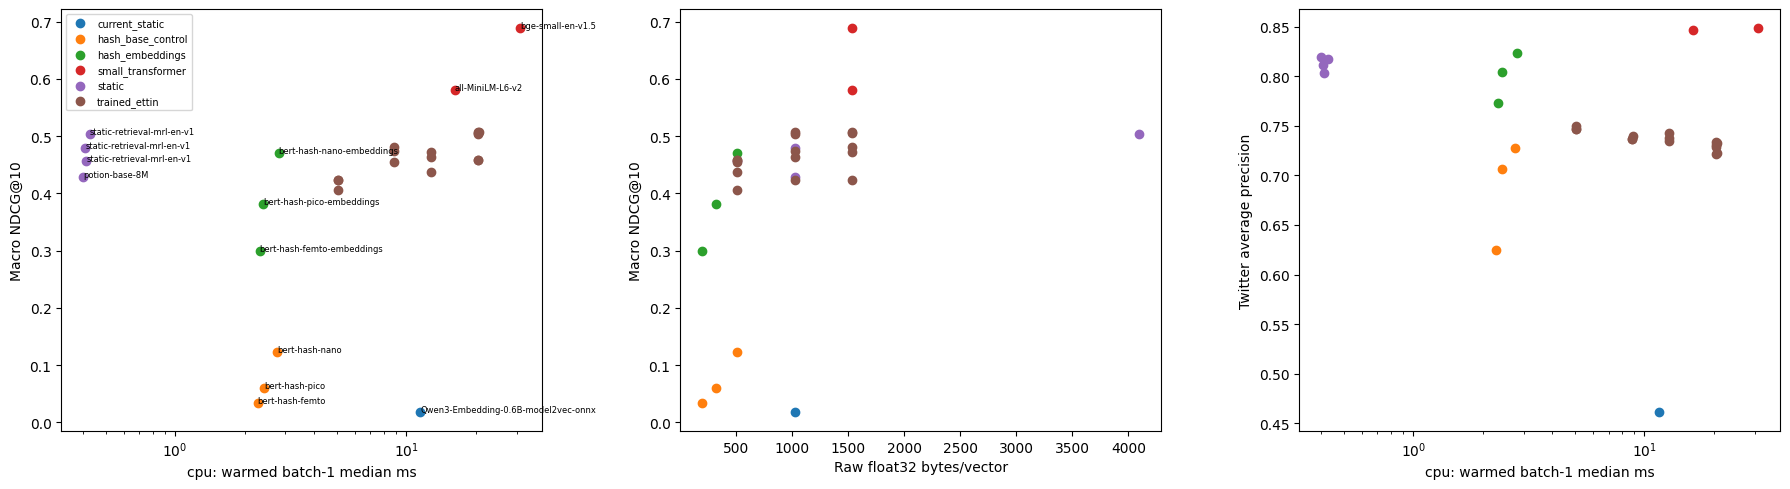

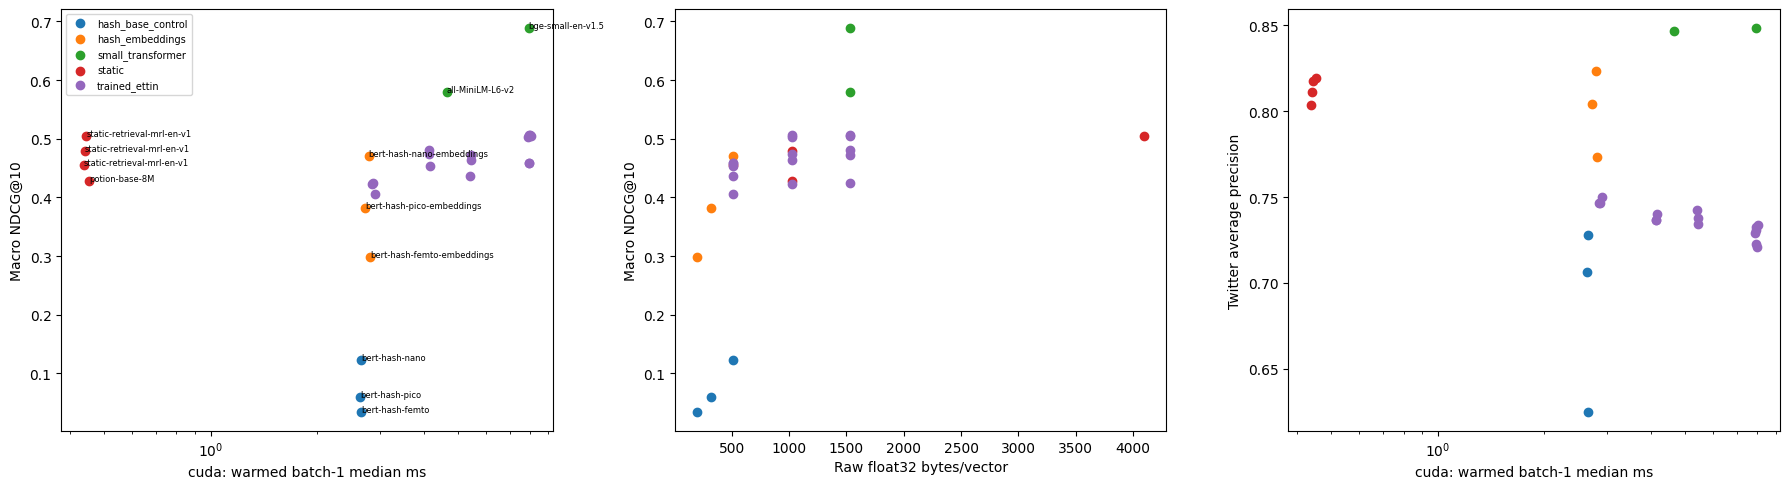

Completed configured experiment. Results: /content/drive/MyDrive/encoder_experiments/bert-hash-l4-01/cfdd396ef971b0e0


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
REPORT=LOCAL/'report';REPORT.mkdir(exist_ok=True)
tasks=json.loads((LOCAL/'data/tasks.json').read_text())
all_scores=[];per_query=[];timings=[]
for spec in MODELS:
    for task in tasks:
        folder=LOCAL/'quality'/spec['slug']/task['name']
        assert W.restore(ROOT/'quality'/spec['slug']/task['name'],folder,CONFIG['contract'])
        all_scores.extend(json.loads((folder/'scores.json').read_text()))
        if (folder/'per-query.json').exists():per_query.extend(json.loads((folder/'per-query.json').read_text()))
    if RUN_LATENCY:
        devices=['cpu']+(['cuda'] if GPU_TIMINGS and spec['group']!='current_static' else [])
        for device in devices:
            folder=LOCAL/'latency'/spec['slug']/device
            assert W.restore(ROOT/'latency'/spec['slug']/device,folder,CONFIG['contract'])
            timings.extend(json.loads((folder/'summary.json').read_text()))
frame=pd.DataFrame(all_scores);frame.to_csv(REPORT/'quality.csv',index=False)
timing=pd.DataFrame(timings);timing.to_csv(REPORT/'latency.csv',index=False)
pq=pd.DataFrame(per_query);pq.to_csv(REPORT/'retrieval-per-query.csv',index=False)
retrieval=frame[frame.kind=='retrieval']
macro=retrieval.groupby(['model','group','depth','dim','mode'],as_index=False).ndcg10.mean()
macro['raw_bytes_per_vector']=4*macro['dim'];macro.to_csv(REPORT/'retrieval-macro.csv',index=False)
display(macro.sort_values('ndcg10',ascending=False))
display(frame[frame.kind=='twitter'][['model','depth','dim','average_precision','auc']])
if RUN_PROBES:display(frame[frame.kind=='probe'].dropna(axis=1,how='all'))
# Paired, stratified query bootstrap. Every profile compared to the current static baseline.
reference='futur/Qwen3-Embedding-0.6B-model2vec-onnx'
differences=[]
if reference in set(pq.model):
    for (model,depth,dim,mode),group in pq.groupby(['model','depth','dim','mode']):
        if model==reference:continue
        rng=np.random.default_rng(CONFIG['seed']);reps=CONFIG['bootstrap_replicates']
        draws=np.zeros(reps);point=0.;names=sorted(group.task.unique())
        for task in names:
            a=group[group.task==task].set_index('query_id').ndcg10
            b=pq[(pq.model==reference)&(pq.task==task)].set_index('query_id').ndcg10
            assert set(a.index)==set(b.index)
            delta=a.reindex(b.index).to_numpy()-b.to_numpy()
            # Shared query resamples within each model comparison, stratified by task.
            sample=delta[rng.integers(len(delta),size=(reps,len(delta)))].mean(1)
            draws+=sample/len(names);point+=float(delta.mean())/len(names)
            differences.append(dict(model=model,depth=int(depth),dim=int(dim),mode=mode,reference=reference,
                task=task,delta=float(delta.mean()),ci_low=float(np.quantile(sample,.025)),ci_high=float(np.quantile(sample,.975)),
                interval='exploratory_95_percent'))
        row=dict(model=model,depth=int(depth),dim=int(dim),mode=mode,reference=reference,task='macro',delta=point,
                 ci_low=float(np.quantile(draws,.025)),ci_high=float(np.quantile(draws,.975)),interval='exploratory_95_percent')
        if (model.startswith('NeuML/') and model.endswith('-embeddings')) or model=='TaylorAI/gte-tiny':
            row.update(primary_family_low=float(np.quantile(draws,.05/(2*3))),
                       primary_family_high=float(np.quantile(draws,1-.05/(2*3))))
        differences.append(row)
# GTE-tiny has its own three-comparator screening family: current static, MiniLM, BGE.
# Its current-static rows were generated above; add the other two matched contrasts here.
gte_id='TaylorAI/gte-tiny'
if gte_id in set(pq.model):
    candidate=pq[pq.model==gte_id]
    for comparator in ('sentence-transformers/all-MiniLM-L6-v2','BAAI/bge-small-en-v1.5'):
        if comparator not in set(pq.model):continue
        rng=np.random.default_rng(CONFIG['seed']);reps=CONFIG['bootstrap_replicates']
        names=sorted(candidate.task.unique());draws=np.zeros(reps);point=0.
        for task in names:
            a=candidate[candidate.task==task].set_index('query_id').ndcg10
            b=pq[(pq.model==comparator)&(pq.task==task)].set_index('query_id').ndcg10
            assert set(a.index)==set(b.index)
            delta=a.reindex(b.index).to_numpy()-b.to_numpy()
            sample=delta[rng.integers(len(delta),size=(reps,len(delta)))].mean(1)
            draws+=sample/len(names);point+=float(delta.mean())/len(names)
            differences.append(dict(model=gte_id,depth=0,dim=384,mode='native',reference=comparator,
                task=task,delta=float(delta.mean()),ci_low=float(np.quantile(sample,.025)),ci_high=float(np.quantile(sample,.975)),
                interval='exploratory_95_percent'))
        differences.append(dict(model=gte_id,depth=0,dim=384,mode='native',reference=comparator,
            task='macro',delta=point,ci_low=float(np.quantile(draws,.025)),ci_high=float(np.quantile(draws,.975)),
            interval='exploratory_95_percent',primary_family_low=float(np.quantile(draws,.05/(2*3))),
            primary_family_high=float(np.quantile(draws,1-.05/(2*3)))))
pd.DataFrame(differences).to_csv(REPORT/'paired-retrieval-differences.csv',index=False)
# Optional cluster bootstrap on Twitter AP. Recompute AP with component multiplicities.
# Precomputed score-tie blocks make weighted AP exact without sorting on every replicate.
TWITTER_CIS=[]
if TWITTER_GROUP_BOOTSTRAP and any(m['id']==reference for m in MODELS):
    reference_spec=next(m for m in MODELS if m['id']==reference)
    def prediction(spec):
        folder=LOCAL/'quality'/spec['slug']/'TwitterURL'
        return np.load(folder/f"predictions-0-{spec['native_dimension']}.npz",allow_pickle=False)
    def ap_function(scores,y):
        order=np.argsort(-scores,kind='stable');s=scores[order];ys=y[order]
        starts=np.r_[0,np.flatnonzero(s[1:]!=s[:-1])+1]
        def ap(weights):
            w=weights[order];positive=np.add.reduceat(w*ys,starts);total=np.add.reduceat(w,starts)
            tp=np.cumsum(positive);n=np.cumsum(total)
            return float(np.sum(positive*np.divide(tp,n,out=np.zeros_like(tp,dtype=float),where=n>0))/tp[-1]) if tp[-1]>0 else np.nan
        return ap
    with prediction(reference_spec) as ref:
        y=ref['labels'];groups=ref['groups'];ref_scores=ref['scores']
    unique,inverse=np.unique(groups,return_inverse=True)
    group_sizes=np.bincount(inverse)
    ref_ap=ap_function(ref_scores,y)
    for spec in MODELS:
        if spec['group']!='hash_embeddings' and spec['id']!='TaylorAI/gte-tiny':continue
        with prediction(spec) as data:
            assert np.array_equal(y,data['labels']) and np.array_equal(groups,data['groups'])
            candidate_scores=data['scores']
        candidate_ap=ap_function(candidate_scores,y);rng=np.random.default_rng(CONFIG['seed']);delta=[]
        for _ in range(CONFIG['bootstrap_replicates']):
            count=np.bincount(rng.integers(len(unique),size=len(unique)),minlength=len(unique))
            weights=count[inverse].astype(float)
            if weights[y==0].sum()==0 or weights[y==1].sum()==0:continue
            delta.append(candidate_ap(weights)-ref_ap(weights))
        assert delta,'No valid bootstrap draws'
        family_size=1 if spec['id']=='TaylorAI/gte-tiny' else 3
        TWITTER_CIS.append(dict(model=spec['id'],reference=reference,valid_replicates=len(delta),
            components=len(unique),largest_component=int(group_sizes.max()),
            delta_ap=candidate_ap(np.ones(len(y)))-ref_ap(np.ones(len(y))),
            ci_low=float(np.quantile(delta,.025)),ci_high=float(np.quantile(delta,.975)),
            primary_family_low=float(np.quantile(delta,.05/(2*family_size))),
            primary_family_high=float(np.quantile(delta,1-.05/(2*family_size)))))
W.write_json(REPORT/'paired-twitter-differences.json',TWITTER_CIS)
# CPU/GPU plots remain separate. Untimed Ettin depths are retained in quality.csv.
if not timing.empty:
    for device in timing.device.unique():
        t=timing[(timing.device==device)&(timing.batch==1)]
        joined=macro.merge(t,on=['model','depth','dim'])
        # Shared-index Ettin is shown separately in CSV; plot the same-encoder setting.
        joined=joined[joined['mode']!='full_corpus']
        fig,axes=plt.subplots(1,3,figsize=(18,5))
        for group,g in joined.groupby('group'):
            axes[0].scatter(g.median_ms,g.ndcg10,label=group)
            axes[1].scatter(g.raw_bytes_per_vector,g.ndcg10,label=group)
        for row in joined.itertuples():
            if row.group!='trained_ettin':
                axes[0].annotate(row.model.split('/')[-1],(row.median_ms,row.ndcg10),fontsize=6)
        axes[0].set(xscale='log',xlabel=f'{device}: warmed batch-1 median ms',ylabel='Macro NDCG@10')
        axes[1].set(xlabel='Raw float32 bytes/vector',ylabel='Macro NDCG@10')
        social=frame[frame.kind=='twitter'].merge(t,on=['model','depth','dim'])
        for group,g in social.groupby('group'):
            axes[2].scatter(g.median_ms,g.average_precision,label=group)
        axes[2].set(xscale='log',xlabel=f'{device}: warmed batch-1 median ms',ylabel='Twitter average precision')
        axes[0].legend(fontsize=7);fig.tight_layout();fig.savefig(REPORT/f'quality-cost-{device}.png',dpi=150);plt.show()
W.write_json(REPORT/'summary.json',dict(smoke=SMOKE,quality_rows=len(frame),timing_rows=len(timing),
    twitter_cluster_intervals=TWITTER_GROUP_BOOTSTRAP,probes=RUN_PROBES,
    note='Frozen L4 screening protocol; no new encoder training. Compare native dimensions and backend labels.'))
W.publish(REPORT,ROOT/'report',CONFIG['contract'])
# The completion marker represents only this exact configured scope.
W.write_json(ROOT/'RUN_COMPLETE.json',dict(contract=CONFIG['contract'],smoke=SMOKE,
    models=[m['id'] for m in MODELS],tasks=tasks,report_manifest_sha256=W.sha(ROOT/'report/COMMITTED.json')))
print('Completed configured experiment. Results:',ROOT)

## 11. Optional synchronization and release
Leave `RELEASE_WHEN_DONE=False` to inspect results interactively. With it enabled, the final cell verifies every completed task, timing and report bundle, requests a Drive flush, then releases the Colab runtime. Any earlier failure stops execution before release. Reopen this notebook with unchanged settings to resume after an interruption.

In [20]:
if RELEASE_WHEN_DONE:
    for spec in MODELS:
        for task in tasks:
            assert W.verified(ROOT/'quality'/spec['slug']/task['name'], CONFIG['contract'])
        if RUN_LATENCY:
            for device in ['cpu'] + (['cuda'] if GPU_TIMINGS and spec['group']!='current_static' else []):
                assert W.verified(ROOT/'latency'/spec['slug']/device, CONFIG['contract'])
    assert W.verified(ROOT/'data', CONFIG['contract'])
    assert W.verified(ROOT/'report', CONFIG['contract'])
    assert json.loads((ROOT/'RUN_COMPLETE.json').read_text())['contract']==CONFIG['contract']
    from google.colab import runtime
    drive.flush_and_unmount(timeout_ms=1200000)
    runtime.unassign()
else:
    print('Results remain on Drive:', ROOT)